# 16. Convective mass transfer

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 7 and 14

When air flows over a wet surface, the vapour that leaves it is swept away by the stream,
just as heat is swept from a warm wall. Chapter 7 found the heat transfer coefficient of a
boundary layer; this chapter finds the *mass transfer coefficient*, and finds it almost for
free. The equation for a dilute species in a boundary layer is the energy equation with the
Prandtl number replaced by the Schmidt number, so every Nusselt-number result of Part II
becomes a Sherwood-number result. The analogy breaks in one place. A fast-evaporating
liquid blows its vapour into the boundary layer, the layer thickens and the transfer slows.
For water at room temperature the effect is a fraction of a per cent; for a volatile
solvent it changes the answer by tens of per cent.

The chapter answers two engineering questions. The first is about drying: how fast does a
solvent-borne coating dry in an air stream, and how much does the choice of solvent
matter? The second is about drops: a dust-suppression spray in an open-pit mine on a hot
summer afternoon in Kazakhstan must wet the haul road three metres below the nozzles. Which
drops arrive, and which evaporate on the way down? The checks solve the boundary layer with
blowing exactly, and the unsteady evaporation of a drop without the quasi-steady
assumption.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

try:
    from engtransport import convection_ext, convective_mass, properties, reference
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    from engtransport import convection_ext, convective_mass, properties, reference
from engtransport.numerics import bisect
from engtransport.plotting import panel_label, use_style

use_style()
M_WATER = 0.018015

## 16.1 The mass transfer coefficient

Let a surface carry a species A at mass fraction $m_s$ next to it, while the stream far
away carries $m_e$. When the transfer is slow, the mass flux of A leaving the surface is
proportional to the difference,

$$
\dot m'' = g^*\left(m_s - m_e\right) ,
\qquad
Sh = \frac{g^* L}{\rho D_{AB}} ,
\tag{16.1}
$$

which defines the *mass transfer conductance* $g^*$, in kg/(m² s), and the Sherwood number
on a length $L$. The conductance is $\rho k_c$, the density times the mass transfer
coefficient $k_c$ in m/s used in chemical engineering; the star marks the low-rate value,
which Section 16.3 corrects. Mass fractions rather than concentrations are used because
the mass balance of a stream is written in them. A vapour at partial pressure $p_v$ in air
at total pressure $P$ has mole fraction $x = p_v/P$ and mass fraction
$m = xM_v/[xM_v + (1-x)M_{air}]$ (`convective_mass.vapour_mass_fraction`).

## 16.2 The analogy with heat transfer

In a laminar boundary layer on a flat plate, a dilute species is carried by the flow and
diffuses across it,

$$
u\frac{\partial m}{\partial x} + v\frac{\partial m}{\partial y}
= D_{AB}\frac{\partial^2 m}{\partial y^2} ,
\tag{16.2}
$$

which is the energy equation of Chapter 7 with $\alpha$ replaced by $D_{AB}$. With the same
boundary conditions (uniform $m_s$ on the plate, $m_e$ outside) the solution is
Pohlhausen's, with the Prandtl number $\nu/\alpha$ replaced by the Schmidt number
$Sc = \nu/D_{AB}$:

$$
Sh_x = 0.332\,Re_x^{1/2}\,Sc^{1/3} ,
\qquad
\overline{Sh}_L = 0.664\,Re_L^{1/2}\,Sc^{1/3} .
\tag{16.3}
$$

Chilton and Colburn (1934) turned this into a rule for any geometry and flow. Define the
heat-transfer factor $j_H = St\,Pr^{2/3}$, with $St = h/(\rho c_p u)$, and the mass-transfer
factor $j_D = St_m Sc^{2/3}$, with $St_m = g^*/(\rho u)$. Where the heat-transfer
correlation goes as $Pr^{1/3}$ the two factors are equal, so a heat transfer coefficient
gives the mass conductance directly:

$$
j_D = j_H ,
\qquad
g^* = \frac{h}{c_p}\left(\frac{Pr}{Sc}\right)^{2/3} = \frac{h}{c_p}\,Le^{-2/3} ,
\tag{16.4}
$$

with the Lewis number $Le = Sc/Pr = \alpha/D_{AB}$. For water vapour in air $Le \approx 0.86$
and $g^* \approx h/c_p$, the basis of the wet-bulb thermometer of Chapter 17. For a drop
or a sphere, Ranz and Marshall (1952) measured the evaporation of drops hanging in an air
stream and found

$$
Sh = 2 + 0.6\,Re_d^{1/2}\,Sc^{1/3} ,
\tag{16.5}
$$

whose first term is the steady diffusion from a sphere into still air (Langmuir 1918).

The Schmidt number sets how thick the concentration layer is compared with the velocity
layer. Water vapour in air has $Sc = 0.61$, so its layer is a little thicker than the
velocity layer, as the thermal layer of air is; the vapours of organic solvents are heavy
molecules that diffuse slowly, with $Sc$ from 1.3 to 1.8 and thinner layers
(Figure 16.1a).

## 16.3 Fast transfer: blowing

The analogy assumes the surface is impermeable to the flow. An evaporating surface is not:
the vapour leaves it, while the air, which does not dissolve in the liquid, has no net flux
through it. The air must therefore diffuse towards the surface as fast as the outward flow
carries it away, as in the Stefan tube of Chapter 14. At the surface the balance of air is
$\dot m''(1 - m_s) = -\rho D_{AB}(\partial m/\partial y)_s$: the total mass flux
$\dot m''$ (all of it vapour) carries air out at $\dot m''(1 - m_s)$, and diffusion of air
inwards cancels it. It is convenient to measure the driving force by the *Spalding mass
transfer number*

$$
B = \frac{m_s - m_e}{1 - m_s} ,
\tag{16.6}
$$

which equals $m_s - m_e$ for a dilute vapour and grows without bound as $m_s \to 1$, when
the surface boils. Across a stagnant film the balance integrates exactly (Spalding 1953),
and gives the *film model* of the blowing effect,

$$
\dot m'' = g^*\ln(1 + B) ,
\qquad
\frac{g}{g^*} = \frac{\ln(1 + B)}{B} ,
\tag{16.7}
$$

where $g = \dot m''/B$ is the conductance at the actual rate. At small $B$ this returns
Eq. (16.1); at large $B$ the outward flow pushes the concentration layer away from the wall,
the gradient there falls and $g/g^*$ drops well below one. For $B < 0$ (condensation of a
vapour onto a cold surface) the flow is towards the wall, the layer is thinned and transfer
is enhanced.

The film model is an assumption about the shape of the layer. In a laminar boundary layer
the blowing can be computed: Hartnett and Eckert (1957) showed that a wall velocity
proportional to $x^{-1/2}$ keeps the layer similar. In the variables of Chapter 7, with
$\eta = y\sqrt{U/(\nu x)}$, stream function $\sqrt{\nu U x}\,f(\eta)$ and
$\phi = (m - m_e)/(m_s - m_e)$, the flow and species equations are $f''' + ff''/2 = 0$ and
$\phi'' + (Sc/2)f\phi' = 0$, and the air balance at the wall becomes

$$
f(0) = \frac{2B}{Sc}\,\phi'(0) ,
\qquad
\frac{g}{g^*} = \frac{\phi'(0)}{\phi'(0)\big|_{B=0}} .
\tag{16.8}
$$

Since $\phi'(0) < 0$, $B > 0$ gives $f(0) < 0$: an outward flow at the wall. The problem is
solved by collocation in `reference.species_similarity`, and Section 16.6 compares it with
the film model.

In [2]:
def solvent_case(name, species, T_s, air, L, U, m_e=0.0):
    """Evaporation of a pure solvent from a plate at T_s into an air stream: Sc, B, and the
    mass flux by the low-rate analogy (16.1), the film model (16.7) and the exact boundary
    layer (16.8)."""
    sat = properties.solvent_saturation(name, T_s)
    D = properties.fuller_diffusivity(species, "Air", T_s)
    Sc = air["nu"] / D
    m_s = convective_mass.vapour_mass_fraction(sat["p_sat"], sat["M"])
    B = convective_mass.spalding_number(m_s, m_e)
    g_star = air["rho"] * D * convective_mass.sherwood_flat_plate(U * L / air["nu"], Sc) / L
    ratio = reference.species_similarity(Sc, B)["dphi0"] / reference.species_similarity(Sc)["dphi0"]
    return {"Sc": Sc, "D": D, "p_sat": sat["p_sat"], "rho_l": sat["rho_l"], "m_s": m_s, "B": B, "g_star": g_star,
            "low": g_star * (m_s - m_e), "film": g_star * math.log1p(B), "exact": g_star * B * ratio, "ratio": ratio}


# Section 16.4: a coated panel in a drying tunnel (assumed conditions)
T_air, U_air, L_panel, wet = 298.15, 3.0, 0.5, 50e-6     # air 25 C at 3 m/s; 0.5 m panel; 50 um of solvent
air25 = properties.dry_air_properties(T_air)
Re_panel = U_air * L_panel / air25["nu"]
solvents = (("ethanol", "C2H5OH"), ("acetone", "C3H6O"), ("diethyl ether", "C4H10O"))
print(f"panel: Re_L = {Re_panel:.3g} (laminar)")
cases = {}
for name, species in solvents:
    c = solvent_case(name, species, T_air, air25, L_panel, U_air)
    cases[name] = c
    print(f"{name:13s}: p_sat = {c['p_sat'] / 1e3:5.1f} kPa, Sc = {c['Sc']:.2f}, m_s = {c['m_s']:.3f}, B = {c['B']:.3f};"
          f" flux low-rate {1e3 * c['low']:.2f}, film {1e3 * c['film']:.2f}, exact {1e3 * c['exact']:.2f} g/(m2 s);"
          f" 50 um dries in {c['rho_l'] * wet / c['exact']:.1f} s (low-rate {c['rho_l'] * wet / c['low']:.1f} s)")

panel: Re_L = 9.62e+04 (laminar)


ethanol      : p_sat =   7.9 kPa, Sc = 1.27, m_s = 0.118, B = 0.134; flux low-rate 0.77, film 0.82, exact 0.80 g/(m2 s); 50 um dries in 49.3 s (low-rate 51.1 s)


acetone      : p_sat =  30.7 kPa, Sc = 1.47, m_s = 0.466, B = 0.873; flux low-rate 2.74, film 3.69, exact 3.27 g/(m2 s); 50 um dries in 12.0 s (low-rate 14.3 s)


diethyl ether: p_sat =  71.5 kPa, Sc = 1.74, m_s = 0.860, B = 6.135; flux low-rate 4.52, film 10.34, exact 7.38 g/(m2 s); 50 um dries in 4.8 s (low-rate 7.8 s)


## 16.4 Drying a solvent coating

Coatings, inks and adhesives are applied dissolved in a solvent, which must then be dried
off in a tunnel of moving air. While the surface is still wet with solvent, the drying rate
is set entirely by the air side: this is the *constant-rate period* of drying, which
Eq. (16.1) or (16.7) describes. To keep the numbers simple, take a panel 0.5 m long in a
stream of air at 3 m/s and 25 °C, wet with 50 μm of pure solvent and held at 25 °C by a
heated platen (assumed conditions; in Chapter 17 the surface finds its own temperature).
The Reynolds number is $9.6\times10^4$, so the layer is laminar and Eq. (16.3) applies.

The three solvents differ mainly in their vapour pressure. Ethanol, at 7.9 kPa, has
$B = 0.13$ and evaporates at 0.80 g/(m² s); the low-rate formula is 4 % low. Acetone, at
30.7 kPa, has $B = 0.87$ and evaporates at 3.27 g/(m² s), 19 % more than the low-rate value
and 11 % less than the film model. Diethyl ether, at 71.5 kPa, has $m_s = 0.86$ and
$B = 6.1$: the exact rate is 7.38 g/(m² s), 63 % above the low-rate formula and 29 % below
the film model. The 50 μm film dries in 49 s, 12 s and 5 s. Blowing is thus not a small
correction for volatile solvents, and the film model overstates it on a flat plate, where
the layer is thin at the leading edge and the vapour has room to spread.

The constant-rate period lasts only while the surface is wet. As the solvent leaves a real
coating the resin concentrates, diffusion of solvent through the drying film takes over,
and the rate falls: the *falling-rate period*, a problem of Chapter 14 inside the coating.
Figure 16.1(b) shows how steeply the rate rises with the surface temperature, and so how
much the heated platen matters: evaporation cools a surface (Chapter 17), and an
unheated panel of ether would soon be far below 25 °C.

In [3]:
# Figure 16.1(a): profiles from the exact boundary layer
prof = {}
for label, Sc, B in (("water vapour, Sc = 0.61", 0.61, 0.0), ("ether, Sc = 1.74", 1.74, 0.0),
                     ("ether, Sc = 1.74, B = 6.1", 1.74, cases["diethyl ether"]["B"])):
    prof[label] = reference.species_similarity(Sc, B)["sol"]
eta_p = np.linspace(0, 8, 300)

# Figure 16.1(b): flux against surface temperature
T_range = {"ethanol": np.linspace(283.15, 313.15, 9), "acetone": np.linspace(283.15, 313.15, 9),
           "diethyl ether": np.linspace(283.15, 303.15, 9)}
flux_T = {}
for name, species in solvents:
    rows = [solvent_case(name, species, T, air25, L_panel, U_air) for T in T_range[name]]
    flux_T[name] = {k: np.array([r[k] for r in rows]) for k in ("low", "film", "exact", "B")}
    print(f"{name:13s}: B from {flux_T[name]['B'][0]:.3f} to {flux_T[name]['B'][-1]:.2f};"
          f" exact flux {1e3 * flux_T[name]['exact'][0]:.2f} to {1e3 * flux_T[name]['exact'][-1]:.2f} g/(m2 s)")

ethanol      : B from 0.051 to 0.34; exact flux 0.30 to 1.89 g/(m2 s)


acetone      : B from 0.361 to 2.54; exact flux 1.61 to 6.15 g/(m2 s)


diethyl ether: B from 1.591 to 14.64; exact flux 4.00 to 9.26 g/(m2 s)


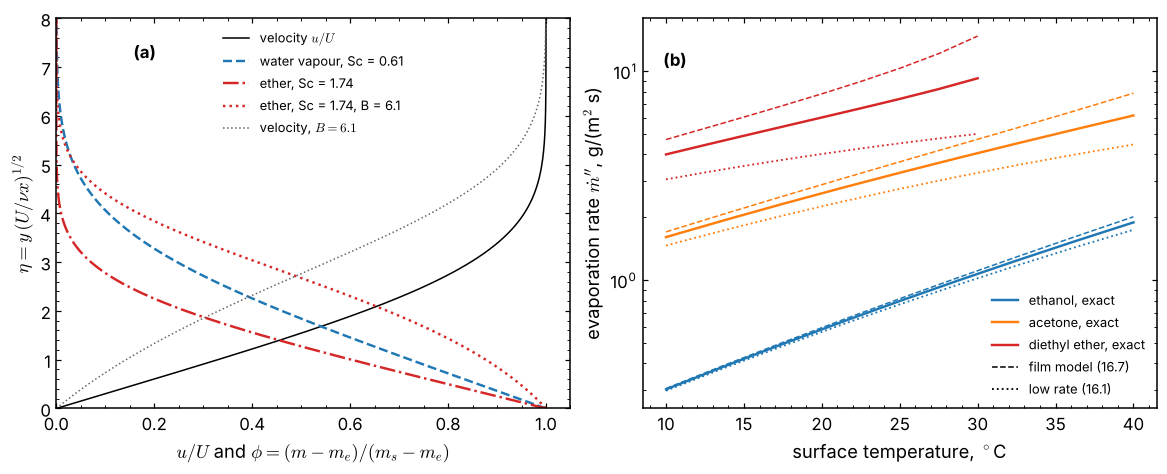

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 4.2))
ax1.plot(prof["water vapour, Sc = 0.61"].sol(eta_p)[1], eta_p, "k-", lw=1.0, label=r"velocity $u/U$")
for (label, sol), style in zip(prof.items(), ("C0--", "C3-.", "C3:")):
    ax1.plot(sol.sol(eta_p)[3], eta_p, style, lw=1.6, label=label)
ax1.plot(prof["ether, Sc = 1.74, B = 6.1"].sol(eta_p)[1], eta_p, ":", color="0.4", lw=1.0,
         label=r"velocity, $B = 6.1$")
ax1.set_xlabel(r"$u/U$ and $\phi = (m - m_e)/(m_s - m_e)$")
ax1.set_ylabel(r"$\eta = y\,(U/\nu x)^{1/2}$")
ax1.set_xlim(0, 1.05)
ax1.set_ylim(0, 8)
ax1.legend(loc="upper center", fontsize=8.5)
panel_label(ax1, "(a)", x=0.15, y=0.94)

for (name, _), color in zip(solvents, ("C0", "C1", "C3")):
    tc = T_range[name] - 273.15
    ax2.semilogy(tc, 1e3 * flux_T[name]["exact"], "-", color=color, label=f"{name}, exact")
    ax2.semilogy(tc, 1e3 * flux_T[name]["film"], "--", color=color, lw=1.0)
    ax2.semilogy(tc, 1e3 * flux_T[name]["low"], ":", color=color, lw=1.2)
ax2.plot([], [], "k--", lw=1.0, label="film model (16.7)")
ax2.plot([], [], "k:", lw=1.2, label="low rate (16.1)")
ax2.set_xlabel(r"surface temperature, $^\circ$C")
ax2.set_ylabel(r"evaporation rate $\dot m''$, g/(m$^2$ s)")
ax2.legend(loc="lower right", fontsize=8.5)
panel_label(ax2, "(b)", x=0.04, y=0.92)
plt.show()

**Figure 16.1.** (a) Velocity and vapour profiles in the laminar boundary layer, exact
similarity solution: water vapour in air, diethyl ether at a low rate, and ether at the
rate of Section 16.4 ($B = 6.1$), whose outward flow pushes both layers from the wall.
(b) Evaporation rate of three solvents from the panel of Section 16.4 against its surface
temperature: exact boundary layer (solid), film model (dashed) and low-rate analogy
(dotted). Air at 25 °C and 3 m/s; panel 0.5 m long.

## 16.5 Drops: the d² law and the Wells curve

A drop of diameter $d$ in still air loses vapour by steady diffusion; the solution for a
sphere with the blowing of Section 16.3 is exact, $\dot m = 2\pi d\rho D_{AB}\ln(1 + B)$,
because the film of a sphere is the whole space outside it. In a stream the rate is
multiplied by $Sh/2$ with $Sh$ from Eq. (16.5). The vapour leaves from the drop's mass
$\rho_l\pi d^3/6$, so

$$
\frac{d(d^2)}{dt} = -K ,
\qquad
K = \frac{4\,Sh\,\rho D_{AB}\ln(1 + B)}{\rho_l} .
\tag{16.9}
$$

At rest $Sh = 2$, $K$ is constant and the square of the diameter falls linearly in time:
the *d² law*, whose lifetime $d_0^2/K$ grows with the square of the initial size. The law
assumes the vapour field around the drop is always the steady one, which holds when the gas
is much less dense than the liquid (Section 16.6).

A drop falling through air reaches its terminal velocity within milliseconds (the time
$\rho_l d^2/18\mu$ is 0.03 s for 100 μm). Its weight then balances the drag,

$$
C_D(Re)\,Re^2 = \frac{4}{3}Ar ,
\qquad
Ar = \frac{d^3\rho(\rho_l - \rho)g}{\mu^2} ,
\tag{16.10}
$$

with the drag coefficient of Brown and Lawler (2003),
$C_D = (24/Re)(1 + 0.150Re^{0.681}) + 0.407/(1 + 8710/Re)$, which reduces to Stokes's law
at small $Re$. As the drop shrinks it falls more slowly, so along its path $dt = 2d\,dd/K(d)$
and $dz = u_t(d)\,dt$, with $Sh$ from the Reynolds number of the moment
(`convective_mass.falling_drop`). The fall before the drop disappears is *Wells's curve*:
Wells (1934) used it to show that drops from a cough smaller than about 0.1 mm evaporate
before they reach the floor and leave their dried residue floating in the room.

The drop's temperature is set by its own evaporation: heat conducted from the air supplies
the latent heat. For a drop at rest ($Nu = Sh = 2$) and a dilute vapour,

$$
k\left(T_e - T_s\right) = \rho D_{AB}\ln(1 + B)\,h_{fg} ,
\tag{16.11}
$$

where $B$ depends on $T_s$ through the vapour pressure; Chapter 17 develops this balance
into the wet-bulb temperature. A water drop has $Pr$ and $Sc$ close to each other, so the
same temperature holds while it falls.

The engineering question is a dust-suppression spray in an open-pit mine. Nozzles 3 m
above a haul road spray water; on a summer afternoon the air is at 35 °C with 20 % relative
humidity, on a mild day at 20 °C with 60 % (assumed conditions). Drops that evaporate on
the way only humidify the air; the useful water is what reaches the road.

In [5]:
def drop_climate(T_e, RH):
    """Drop temperature from Eq. (16.11) and the gas properties at the film temperature."""
    m_e = convective_mass.vapour_mass_fraction(RH * properties.saturation_pressure_water(T_e), M_WATER)

    def balance(T_s):
        T_f = 0.5 * (T_s + T_e)
        air = properties.dry_air_properties(T_f)
        D = properties.water_vapour_diffusivity_air(T_f)
        m_s = convective_mass.vapour_mass_fraction(properties.saturation_pressure_water(T_s), M_WATER)
        B = convective_mass.spalding_number(m_s, m_e)
        return air["k"] * (T_e - T_s) - air["rho"] * D * math.log1p(B) * properties.saturated_water(T_s)["h_fg"]

    T_s = bisect(balance, 274.0, T_e - 1e-6, xtol=1e-9)[0]
    T_f = 0.5 * (T_s + T_e)
    air = properties.dry_air_properties(T_f)
    D = properties.water_vapour_diffusivity_air(T_f)
    m_s = convective_mass.vapour_mass_fraction(properties.saturation_pressure_water(T_s), M_WATER)
    return {"T_s": T_s, "air": air, "D": D, "Sc": air["nu"] / D, "m_e": m_e, "m_s": m_s,
            "B": convective_mass.spalding_number(m_s, m_e), "rho_l": properties.water_properties(T_s)["rho"]}


def fall(d0, cl, **kw):
    a = cl["air"]
    return convective_mass.falling_drop(d0, cl["rho_l"], a["rho"], a["mu"], cl["D"], cl["B"], cl["Sc"], **kw)


H_nozzle = 3.0
climates = {"summer, 35 C, 20 %": drop_climate(308.15, 0.20), "mild, 20 C, 60 %": drop_climate(293.15, 0.60)}
for label, cl in climates.items():
    print(f"{label}: drop at {cl['T_s'] - 273.15:.1f} C, Sc = {cl['Sc']:.3f}, B = {cl['B']:.4f}")
    for d0 in (20e-6, 50e-6, 100e-6, 150e-6, 200e-6):
        r = fall(d0, cl)
        K0 = convective_mass.d2_law_rate(d0, cl["air"]["rho"], cl["D"], cl["rho_l"], cl["B"])
        print(f"   d0 = {1e6 * d0:3.0f} um: lifetime {r['t_life']:6.2f} s falling ({d0**2 / K0:6.2f} s at rest),"
              f" falls {r['z_life']:6.3f} m; terminal velocity at start {r['u'][0]:.3f} m/s")
    cl["d_crit"] = bisect(lambda d: fall(d, cl)["z_life"] - H_nozzle, 20e-6, 1e-3, xtol=1e-9)[0]
    print(f"   drops smaller than {1e6 * cl['d_crit']:.0f} um evaporate before falling {H_nozzle:g} m")

summer, 35 C, 20 %: drop at 18.1 C, Sc = 0.611, B = 0.0060
   d0 =  20 um: lifetime   0.27 s falling (  0.28 s at rest), falls  0.002 m; terminal velocity at start 0.012 m/s
   d0 =  50 um: lifetime   1.61 s falling (  1.72 s at rest), falls  0.056 m; terminal velocity at start 0.070 m/s
   d0 = 100 um: lifetime   5.84 s falling (  6.89 s at rest), falls  0.724 m; terminal velocity at start 0.244 m/s
   d0 = 150 um: lifetime  11.86 s falling ( 15.51 s at rest), falls  2.879 m; terminal velocity at start 0.467 m/s
   d0 = 200 um: lifetime  19.17 s falling ( 27.57 s at rest), falls  7.171 m; terminal velocity at start 0.704 m/s
   drops smaller than 152 um evaporate before falling 3 m
mild, 20 C, 60 %: drop at 14.9 C, Sc = 0.611, B = 0.0018
   d0 =  20 um: lifetime   0.92 s falling (  0.94 s at rest), falls  0.005 m; terminal velocity at start 0.012 m/s
   d0 =  50 um: lifetime   5.46 s falling (  5.85 s at rest), falls  0.194 m; terminal velocity at start 0.071 m/s
   d0 = 100 um: lifet

   drops smaller than 106 um evaporate before falling 3 m


In [6]:
# Figure 16.2 data
summer = climates["summer, 35 C, 20 %"]
traj = {d0: fall(d0, summer) for d0 in (50e-6, 100e-6, 150e-6)}
d0_grid = np.geomspace(10e-6, 400e-6, 40)
wells = {label: np.array([fall(d, cl)["z_life"] for d in d0_grid]) for label, cl in climates.items()}
RH_grid = np.linspace(0.1, 0.9, 9)
d_crit_RH = {}
for T_e in (293.15, 308.15):
    vals = []
    for RH in RH_grid:
        cl = drop_climate(T_e, RH)
        vals.append(bisect(lambda d: fall(d, cl)["z_life"] - H_nozzle, 10e-6, 2e-3, xtol=1e-9)[0])
    d_crit_RH[T_e] = np.array(vals)
    print(f"T = {T_e - 273.15:.0f} C: critical diameter from {1e6 * vals[0]:.0f} um (RH 10 %) to {1e6 * vals[-1]:.0f} um (RH 90 %)")

T = 20 C: critical diameter from 139 um (RH 10 %) to 71 um (RH 90 %)


T = 35 C: critical diameter from 160 um (RH 10 %) to 78 um (RH 90 %)


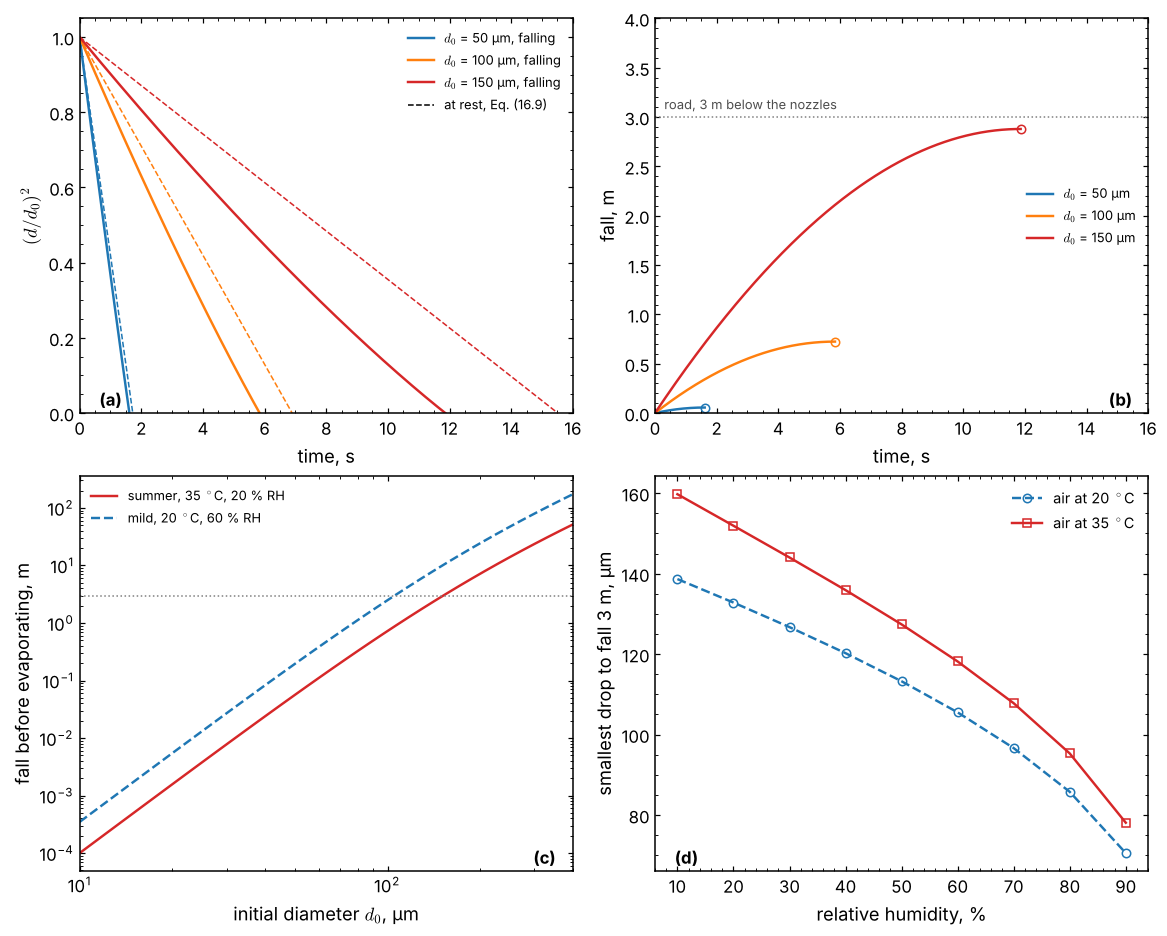

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes
for (d0, r), color in zip(traj.items(), ("C0", "C1", "C3")):
    K0 = convective_mass.d2_law_rate(d0, summer["air"]["rho"], summer["D"], summer["rho_l"], summer["B"])
    ax1.plot(r["t"], (r["d"] / d0) ** 2, "-", color=color, label=fr"$d_0$ = {1e6 * d0:.0f} μm, falling")
    t_rest = np.linspace(0, d0**2 / K0, 50)
    ax1.plot(t_rest, 1 - K0 * t_rest / d0**2, "--", color=color, lw=1.0)
ax1.plot([], [], "k--", lw=1.0, label="at rest, Eq. (16.9)")
ax1.set_xlabel("time, s")
ax1.set_ylabel(r"$(d/d_0)^2$")
ax1.set_xlim(0, 16)
ax1.set_ylim(0, 1.05)
ax1.legend(loc="upper right", fontsize=8.5)
panel_label(ax1, "(a)", x=0.04, y=0.06)

for (d0, r), color in zip(traj.items(), ("C0", "C1", "C3")):
    ax2.plot(r["t"], r["z"], "-", color=color, label=fr"$d_0$ = {1e6 * d0:.0f} μm")
    ax2.plot(r["t"][-1], r["z"][-1], "o", color=color, mfc="none")
ax2.axhline(H_nozzle, color="0.5", ls=":", lw=1.0)
ax2.text(0.3, H_nozzle + 0.08, "road, 3 m below the nozzles", fontsize=8.5, color="0.3")
ax2.set_xlabel("time, s")
ax2.set_ylabel("fall, m")
ax2.set_xlim(0, 16)
ax2.set_ylim(0, 4)
ax2.legend(loc="center right", fontsize=8.5)
panel_label(ax2, "(b)", x=0.92, y=0.06)

for (label, z), style in zip(wells.items(), ("C3-", "C0--")):
    ax3.loglog(1e6 * d0_grid, z, style, label=label.replace(" C,", r" $^\circ$C,").replace(" %", r" % RH"))
ax3.axhline(H_nozzle, color="0.5", ls=":", lw=1.0)
ax3.set_xlabel(r"initial diameter $d_0$, μm")
ax3.set_ylabel("fall before evaporating, m")
ax3.set_xlim(10, 400)
ax3.legend(loc="upper left", fontsize=8.5)
panel_label(ax3, "(c)", x=0.92, y=0.06)

for T_e, style in ((293.15, "C0o--"), (308.15, "C3s-")):
    ax4.plot(100 * RH_grid, 1e6 * d_crit_RH[T_e], style, mfc="none", label=fr"air at {T_e - 273.15:.0f} $^\circ$C")
ax4.set_xlabel("relative humidity, %")
ax4.set_ylabel(r"smallest drop to fall 3 m, μm")
ax4.legend(loc="upper right")
panel_label(ax4, "(d)", x=0.04, y=0.06)
plt.show()

**Figure 16.2.** Water drops from a dust-suppression spray. (a) Square of the diameter
against time in air at 35 °C and 20 % relative humidity, falling (solid) and at rest
(dashed, the d² law). (b) Fall against time; circles mark where the drop is gone.
(c) Wells's curve: fall before evaporation against initial size, on a summer and a mild
day. (d) Smallest drop that reaches the road 3 m below, against relative humidity.

In the summer air the drop sits at 18.1 °C, and $B = 0.006$: for water, blowing is
irrelevant and the low-rate analogy is exact to 0.3 %. A 50 μm drop lives 1.6 s and falls
6 cm; a 100 μm drop lives 5.8 s and falls 0.72 m; a 150 μm drop falls 2.9 m in 11.9 s, and
just fails to reach the road. Falling shortens the life of the larger drops by up to a
third, because their own motion ventilates them. The smallest drop that reaches the road is
152 μm in summer and 106 μm on the mild day; at 35 °C it rises to 160 μm at 10 %
humidity and falls to 78 μm at 90 %. Dust is caught best by drops not much larger than the dust, so a
spray in a hot dry pit has a narrow window: drops a few hundred micrometres across reach
the road, and anything finer only cools and humidifies the air (the subject of Chapter 17).

## 16.6 Checks

Three of the results rest on assumptions that can be removed: the analogy with Pr ≠ Sc, the
film model of blowing, and the quasi-steady d² law.

*The analogy.* The similarity equations of Section 16.3 with $B = 0$ give the exact
low-rate Sherwood number at any Schmidt number. Compared with Eq. (16.3), and with the
Chilton–Colburn route (16.4) from the exact Nusselt number of air ($Pr = 0.71$), they test
the $Sc^{1/3}$ law between gases, liquids and the solvents of Section 16.4.

*Blowing.* Equation (16.8) is solved for $-0.6 \le B \le 7$ and compared with the film
model (16.7). Much beyond $B = 7$ the wall shear of the water-vapour layer has fallen below
a tenth of its value without blowing: the layer is close to being blown off the wall, and
the similarity solution is not continued.

*The d² law.* For a drop put into still, vapour-free gas, the unsteady vapour equation
with the Stefan flow and the shrinking surface is solved without any quasi-steady
assumption. With $s = \ln(r/R)$ and a time $\tau$ stretched by $d\tau = D\,dt/R^2$, it reads

$$
\frac{\partial m}{\partial \tau}
= e^{-2s}\left(\frac{\partial^2 m}{\partial s^2} + \frac{\partial m}{\partial s}\right)
- G\left[\varepsilon + (1 - \varepsilon)e^{-3s}\right]\frac{\partial m}{\partial s} ,
\qquad
\frac{d\ln R^2}{d\tau} = -2\varepsilon G ,
\tag{16.12}
$$

with $\varepsilon = \rho/\rho_l$ and $G = -(\partial m/\partial s)_0/(1 - m_s)$, which gives
the rate $\dot m = 4\pi R\rho DG$; the quasi-steady value is $G = \ln(1 + B)$
(`reference.drop_evaporation_transient`). The first term is diffusion in the stretched
coordinates, the second the radial flow of the gas, partly the Stefan flow and partly the
gas moving in behind the receding surface.

In [8]:
# (a) the analogy with Pr != Sc
Sc_grid = np.geomspace(0.3, 10.0, 16)
Pr_air = 0.71
Nu_air = reference.similarity_bvp(Pr_air)["dtheta0"]
Sh_exact = np.array([-reference.species_similarity(Sc)["dphi0"] for Sc in Sc_grid])
Sh_33 = 0.332057 * np.cbrt(Sc_grid)
Sh_cc = Nu_air * np.cbrt(Sc_grid / Pr_air)
print(f"Sh_x/Re_x^0.5 exact against 0.332 Sc^(1/3): {100 * (Sh_exact / Sh_33 - 1).min():+.2f} to {100 * (Sh_exact / Sh_33 - 1).max():+.2f} %")
print(f"against Chilton-Colburn from Nu of air: {100 * (Sh_exact / Sh_cc - 1).min():+.2f} to {100 * (Sh_exact / Sh_cc - 1).max():+.2f} %")
mid = (Sc_grid >= 0.6) & (Sc_grid <= 1.8)
print(f"for 0.6 <= Sc <= 1.8: {100 * np.abs(Sh_exact / Sh_33 - 1)[mid].max():.2f} % and {100 * np.abs(Sh_exact / Sh_cc - 1)[mid].max():.2f} %")
print(f"pohlhausen_heat_transfer(Sc) at Sc = 2.5: {convection_ext.pohlhausen_heat_transfer(2.5):.6f};"
      f" species_similarity: {-reference.species_similarity(2.5)['dphi0']:.6f}")

# (b) blowing
B_grid = np.array([-0.6, -0.5, -0.4, -0.3, -0.2, -0.1, 0.05, 0.1, 0.2, 0.5, 1.0, 2.0, 3.0, 4.0, 5.5, 7.0])
blow = {}
for Sc in (0.61, 1.74):
    base = reference.species_similarity(Sc)["dphi0"]
    blow[Sc] = np.array([reference.species_similarity(Sc, B)["dphi0"] / base for B in B_grid])
    film = convective_mass.film_blowing_factor(B_grid)
    print(f"Sc = {Sc}: wall shear f''(0) at B = 7 is {reference.species_similarity(Sc, 7.0)['fpp0']:.4f} (0.3321 without blowing)")
    print(f"Sc = {Sc}: B = " + ", ".join(f"{B:.2f}: exact {gb:.3f}, film {gf:.3f} ({100 * (gf / gb - 1):+.0f} %)"
                                       for B, gb, gf in zip(B_grid, blow[Sc], film) if B in (-0.5, 0.2, 0.5, 2.0, 7.0)))

# (c), (d) unsteady drop
drops_t = {eps: reference.drop_evaporation_transient(1.0, eps, s_max=math.log(1e4)) for eps in (1e-3, 1e-2, 1e-1)}
dev = []
for B in (0.006, 0.1, 1.0, 6.0):
    for eps in (1e-3, 3e-3, 1e-2, 3e-2, 1e-1):
        r = reference.drop_evaporation_transient(B, eps, s_max=math.log(1e4))
        t_qs = (1 - 0.01) / (2 * eps * math.log1p(B))
        dev.append((B, eps, r["t"][-1] / t_qs - 1))
dev = np.array(dev)
for B, eps, e in dev:
    if eps in (1e-3, 1e-1):
        print(f"B = {B:5.3f}, eps = {eps:.0e}: lifetime to R^2 = 0.01 R0^2 is {100 * e:+.2f} % off the d2 law")
for B, eps, e in dev:
    if eps == 1e-2:
        print(f"B = {B:5.3f}, eps = 1e-02: {100 * e:+.2f} %")
x_col = np.sqrt(dev[:, 1] * np.log1p(dev[:, 0]))
coef = np.sum(x_col * -dev[:, 2]) / np.sum(x_col**2)
print(f"collapse: shortening ~ {coef:.3f} sqrt(eps ln(1+B)); spread {100 * np.max(np.abs(-dev[:, 2] / (coef * x_col) - 1)):.0f} %")
water = summer["air"]["rho"] / summer["rho_l"]
print(f"water drop of Section 16.5: eps = {water:.2e}, B = {summer['B']:.4f}: predicted shortening"
      f" {100 * coef * math.sqrt(water * math.log1p(summer['B'])):.2f} %")

Sh_x/Re_x^0.5 exact against 0.332 Sc^(1/3): -3.39 to +1.78 %
against Chilton-Colburn from Nu of air: -2.71 to +2.50 %
for 0.6 <= Sc <= 1.8: 1.09 % and 1.36 %


pohlhausen_heat_transfer(Sc) at Sc = 2.5: 0.455829; species_similarity: 0.455828


Sc = 0.61: wall shear f''(0) at B = 7 is 0.0253 (0.3321 without blowing)
Sc = 0.61: B = -0.50: exact 1.656, film 1.386 (-16 %), 0.20: exact 0.868, film 0.912 (+5 %), 0.50: exact 0.727, film 0.811 (+12 %), 2.00: exact 0.405, film 0.549 (+36 %), 7.00: exact 0.165, film 0.297 (+80 %)


Sc = 1.74: wall shear f''(0) at B = 7 is 0.1138 (0.3321 without blowing)
Sc = 1.74: B = -0.50: exact 1.582, film 1.386 (-12 %), 0.20: exact 0.882, film 0.912 (+3 %), 0.50: exact 0.753, film 0.811 (+8 %), 2.00: exact 0.452, film 0.549 (+21 %), 7.00: exact 0.208, film 0.297 (+43 %)


B = 0.006, eps = 1e-03: lifetime to R^2 = 0.01 R0^2 is -0.18 % off the d2 law
B = 0.006, eps = 1e-01: lifetime to R^2 = 0.01 R0^2 is -1.96 % off the d2 law
B = 0.100, eps = 1e-03: lifetime to R^2 = 0.01 R0^2 is -0.79 % off the d2 law
B = 0.100, eps = 1e-01: lifetime to R^2 = 0.01 R0^2 is -7.46 % off the d2 law
B = 1.000, eps = 1e-03: lifetime to R^2 = 0.01 R0^2 is -2.12 % off the d2 law
B = 1.000, eps = 1e-01: lifetime to R^2 = 0.01 R0^2 is -17.39 % off the d2 law
B = 6.000, eps = 1e-03: lifetime to R^2 = 0.01 R0^2 is -3.40 % off the d2 law
B = 6.000, eps = 1e-01: lifetime to R^2 = 0.01 R0^2 is -24.36 % off the d2 law
B = 0.006, eps = 1e-02: -0.61 %
B = 0.100, eps = 1e-02: -2.48 %
B = 1.000, eps = 1e-02: -6.33 %
B = 6.000, eps = 1e-02: -9.69 %
collapse: shortening ~ 0.617 sqrt(eps ln(1+B)); spread 31 %
water drop of Section 16.5: eps = 1.18e-03, B = 0.0060: predicted shortening 0.16 %


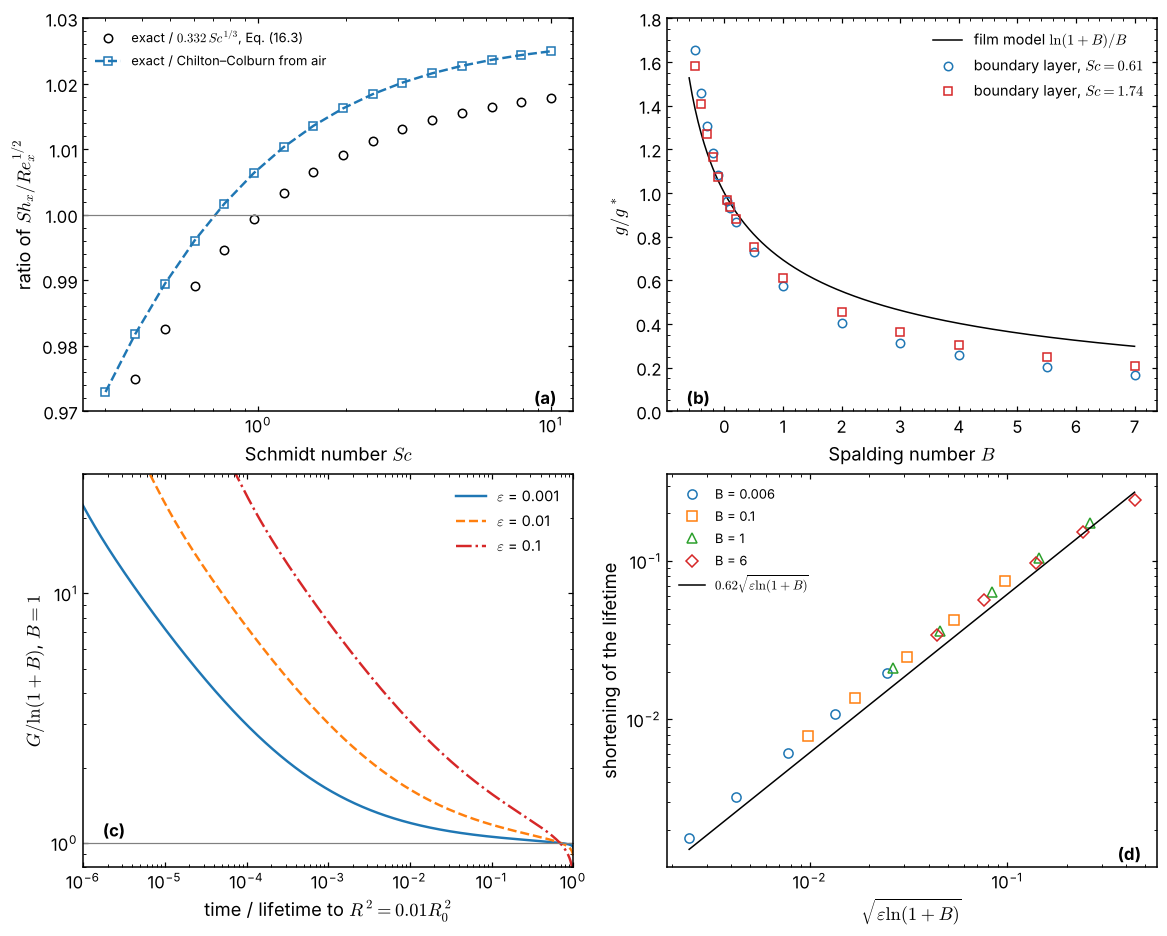

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.4))
(ax1, ax2), (ax3, ax4) = axes
ax1.semilogx(Sc_grid, Sh_exact / Sh_33, "ko", mfc="none", label=r"exact / $0.332\,Sc^{1/3}$, Eq. (16.3)")
ax1.semilogx(Sc_grid, Sh_exact / Sh_cc, "C0s--", ms=5, mfc="none", label="exact / Chilton–Colburn from air")
ax1.axhline(1.0, color="0.5", lw=0.8)
ax1.set_xlabel(r"Schmidt number $Sc$")
ax1.set_ylabel(r"ratio of $Sh_x/Re_x^{1/2}$")
ax1.set_ylim(0.97, 1.03)
ax1.legend(loc="upper left", fontsize=8.5)
panel_label(ax1, "(a)", x=0.92, y=0.06)

Bf = np.linspace(-0.6, 7, 300)
ax2.plot(Bf, convective_mass.film_blowing_factor(Bf), "k-", lw=1.0, label=r"film model $\ln(1+B)/B$")
ax2.plot(B_grid, blow[0.61], "C0o", mfc="none", label=r"boundary layer, $Sc = 0.61$")
ax2.plot(B_grid, blow[1.74], "C3s", ms=5, mfc="none", label=r"boundary layer, $Sc = 1.74$")
ax2.set_xlabel(r"Spalding number $B$")
ax2.set_ylabel(r"$g/g^*$")
ax2.set_ylim(0, 1.8)
ax2.legend(loc="upper right")
panel_label(ax2, "(b)", x=0.04, y=0.06)

for (eps, r), style in zip(drops_t.items(), ("C0-", "C1--", "C3-.")):
    t_life = r["t"][-1]
    ax3.loglog(r["t"][1:] / t_life, r["G"][1:] / math.log1p(1.0), style, label=fr"$\varepsilon$ = {eps:g}")
ax3.axhline(1.0, color="0.5", lw=0.8)
ax3.set_xlabel(r"time / lifetime to $R^2 = 0.01R_0^2$")
ax3.set_ylabel(r"$G/\ln(1 + B)$, $B = 1$")
ax3.set_xlim(1e-6, 1)
ax3.set_ylim(0.8, 30)
ax3.legend(loc="upper right")
panel_label(ax3, "(c)", x=0.04, y=0.12)

for B, marker in zip((0.006, 0.1, 1.0, 6.0), ("o", "s", "^", "D")):
    sel = dev[:, 0] == B
    ax4.loglog(x_col[sel], -dev[sel, 2], marker, mfc="none", ms=6, label=f"B = {B:g}")
xx = np.geomspace(x_col.min(), x_col.max(), 10)
ax4.loglog(xx, coef * xx, "k-", lw=1.0, label=fr"${coef:.2f}\sqrt{{\varepsilon\ln(1+B)}}$")
ax4.set_xlabel(r"$\sqrt{\varepsilon\ln(1 + B)}$")
ax4.set_ylabel("shortening of the lifetime")
ax4.legend(loc="upper left", fontsize=8.5)
panel_label(ax4, "(d)", x=0.92, y=0.06)
plt.show()

**Figure 16.3.** Checks. (a) Exact low-rate Sherwood number of the laminar flat plate
against Eq. (16.3) and against the Chilton–Colburn route from the exact Nusselt number of
air. (b) Blowing: conductance ratio of the exact boundary layer, Eq. (16.8), for water
vapour and ether, against the film model (16.7). (c) Evaporation rate of a drop put into
still gas, from the unsteady equations (16.12), over its quasi-steady value, for three
gas-to-liquid density ratios. (d) Shortening of the lifetime with respect to the d² law
against $\sqrt{\varepsilon\ln(1 + B)}$, for 20 combinThe exact Sherwood number differs from $0.332\,Sc^{1/3}$ by $-3.4$ to $+1.8$ % between
$Sc = 0.3$ and 10, and by at most 1.1 % for the gases and vapours of this chapter
($0.6 \le Sc \le 1.8$); the Chilton–Colburn value built on air is within 1.4 % there.
The $Sc^{1/3}$ law is thus accurate when Pr ≠ Sc, and the solver reproduces the Pohlhausen
integral of Chapter 7 to six digits. Blowing is another matter. The film model is within
5 % of the boundary layer for $B \le 0.2$, but overstates its conductance by 8 to 12 % at
$B = 0.5$, by 21 to 36 % at $B = 2$ and by 43 to 80 % at $B = 7$, the more so for the
lower Schmidt number; for suction ($B = -0.5$) it understates it by 12 to 16 %. The flat
plate, where the layer starts thin, is where the film model does badly; for a drop at rest
it is exact. The unsteady drop starts with the large flux of a fresh diffusion layer, which
decays to the quasi-steady value long before the drop has shrunk (panel c). The early
excess shortens the life by roughly $0.6\sqrt{\varepsilon\ln(1 + B)}$, to within a third,
panel (d): 0.2 % for the water drops of Section 16.5, 6 % for a drop with $B = 1$ in a gas a
hundredth as dense as the liquid, and 17 to 24 % at a tenth, the densities of a diesel
engine. At atmospheric pressure the d² law is exact enough.pressure.

## 16.7 What to trust

* *The analogy* (16.3)–(16.5) is accurate when the transfer is slow, the properties are
  uniform, and the heat-transfer correlation used has the right Reynolds-number form. In
  turbulent flow the Schmidt-number exponent differs slightly from 1/3: Gilliland and
  Sherwood (1934) found 0.44 in a wetted-wall column (Exercise 2).
* *Blowing.* For $B > 0.2$ the film model can be tens of per cent wrong on a flat plate;
  use the boundary-layer value where it applies, and treat correlations for other shapes
  with similar caution. For water at ordinary temperatures $B < 0.05$ and blowing does not
  matter.
* *Surface conditions.* The coating of Section 16.4 was held at a fixed temperature; in
  practice evaporative cooling sets it (Chapter 17), and the resin slows drying once the
  surface is no longer wet.
* *Drops* in a spray interact: they humidify and cool the air around them, which slows
  their evaporation, and they do not all fall in still air. Wells's curve is the limit of
  an isolated drop; its threshold diameters are estimates to perhaps 20 %.

## Summary

* The mass transfer conductance (16.1) is found from the heat transfer results of Part II
  by replacing $Pr$ with $Sc$, Eqs. (16.2)–(16.3); the Chilton–Colburn analogy (16.4)
  converts a heat transfer coefficient directly, and Eq. (16.5) serves drops.
* When the vapour is not dilute, the Spalding number (16.6) measures the driving force and
  blowing reduces the conductance; the film model (16.7) is exact for a sphere and overstates
  the conductance of a flat plate, Eq. (16.8).
* A solvent coating dries at 0.8 to 7.4 g/(m² s) in the tunnel of Section 16.4, depending on
  the solvent; for ether the low-rate formula is 39 % low and the film model 40 % high.
* A drop's diameter squared falls linearly, Eq. (16.9). In hot dry air, spray drops smaller
  than about 0.15 mm evaporate before falling 3 m (Wells's curve).

## Exercises

Sample solutions are in [`solutions/part4_mass_transfer/16_solutions.ipynb`](../../solutions/part4_mass_transfer/16_solutions.ipynb).

1. **A solvent spill.** One litre of acetone spills on a laboratory floor and spreads into
   a pool of 1 m² (take it square, 1 m along the air flow). The ventilation moves air at
   20 °C over it at 0.5 m/s. Taking the pool at the air temperature (an assumption: the
   concrete supplies the latent heat), how long does the pool take to evaporate, by the
   low-rate analogy, the film model and the exact boundary layer? How many cubic metres of
   air per minute must the room's extraction carry to keep the average acetone in the
   extract below 2.5 % by volume (the lower explosive limit), if the flow is uniform?
2. **The wetted-wall column.** Gilliland and Sherwood (1934) evaporated liquids from the
   wetted wall of a 25 mm tube into turbulent air, and correlated their data as
   $Sh = 0.023\,Re^{0.83}Sc^{0.44}$. The Chilton–Colburn analogy applied to the
   Dittus–Boelter equation gives $Sh = 0.023\,Re^{0.8}Sc^{1/3}$. Compare the two for water,
   ethanol and diethyl ether vapours in air at $Re = 10^4$ and $3\times10^4$. Then find the
   length of tube in which air at 25 °C entering dry at $Re = 10^4$ reaches 90 % of
   saturation with water at 25 °C, by both formulas.
3. **Condensing steam from a mixture.** A steam–air mixture at 1 atm, 50 % steam by
   volume, flows at 2 m/s over a plate 0.3 m long cooled to 40 °C, on which the steam
   condenses. Take the gas properties of air at 60 °C and $D = 3.0\times10^{-5}$ m²/s for
   steam in air (assumed values). Find $B$, and the condensation rate by the low-rate
   analogy, the film model and the exact boundary layer. Why does the air make the
   condenser so much worse than one for pure steam, and why does the flow towards the wall
   help?
4. **What reaches the road.** The nozzles of Section 16.5 produce drops whose mass is
   distributed log-normally in diameter, with a mass median diameter of 120 μm and a
   geometric standard deviation of 1.6 (assumed). What fraction of the water reaches the
   road 3 m below on the summer and the mild day, counting the drops that arrive partly
   evaporated? What mass median diameter would deliver 90 % in summer?

## Suggested references

* T. H. Chilton and A. P. Colburn, "Mass transfer (absorption) coefficients: prediction
  from data on heat transfer and fluid friction", *Ind. Eng. Chem.* **26**, 1183 (1934).
* E. R. Gilliland and T. K. Sherwood, "Diffusion of vapors into air streams", *Ind. Eng.
  Chem.* **26**, 516 (1934).
* I. Langmuir, "The evaporation of small spheres", *Phys. Rev.* **12**, 368 (1918).
* W. E. Ranz and W. R. Marshall, "Evaporation from drops", *Chem. Eng. Prog.* **48**, 141
  and 173 (1952).
* D. B. Spalding, "The combustion of liquid fuels", *Proc. Combust. Inst.* **4**, 847
  (1953).
* J. P. Hartnett and E. R. G. Eckert, "Mass-transfer cooling in a laminar boundary layer
  with constant fluid properties", *Trans. ASME* **79**, 247 (1957).
* A. Acrivos, "Mass transfer in laminar-boundary-layer flows with finite interfacial
  velocities", *AIChE J.* **6**, 410 (1960).
* W. F. Wells, "On air-borne infection. Study II. Droplets and droplet nuclei", *Am. J.
  Hyg.* **20**, 611 (1934).
* P. P. Brown and D. F. Lawler, "Sphere drag and settling velocity revisited", *J. Environ.
  Eng.* **129**, 222 (2003).

---

**Previous:** [15. Diffusion with reaction](15_diffusion_reaction.ipynb) &nbsp;·&nbsp; **Next:** [17. Simultaneous heat and mass transfer](17_simultaneous_heat_mass.ipynb)